# Custom CNN - AQUA20 Underwater Species Classification

| | |
|---|---|
| **Member** | IT25101088 |
| **Model** | Custom CNN |
| **Model family** | Deep learning (convolutional neural network) |
| **Pipeline branch** | A - deep learning on images |
| **Main metric** | Macro F1 (every species counts equally - AQUA20 is heavily imbalanced) |

A convolutional neural network built from scratch in Keras. Convolution layers learn their own filters (edges -> textures -> body parts) directly from the pixels, instead of relying on hand-made features like HOG. It is the only model in the group that sees the **images themselves**.

**How this notebook fits the group pipeline:** label encoding, the fixed stratified train/validation split
(`data/splits/split_indices.csv`), resizing, CLAHE and normalization all come from the shared code in
`scripts/preprocessing.py` (the group's preprocessing stage). This notebook only adds the model-specific
steps, so every member trains and tests on exactly the same images.

## 1. Why a CNN suits AQUA20

- **Images are spatial data:** convolutions share weights across positions, so a fin or tentacle is
  recognised wherever it appears in the frame - something a flat model (LR, MLP) cannot do.
- **Learned features:** the network learns which colours, textures and shapes separate the species,
  including under poor underwater lighting.
- **Augmentation fits naturally:** random flips, rotations, zooms and brightness changes (from the group's
  augmentation step) are layers inside the model, active only during training.
- **CLAHE matters most here:** the CNN reads colour and contrast directly, so this is where the CLAHE colour
  correction from the preprocessing stage should have the clearest effect.
- **Constraint:** no GPU, so the network is small (3 conv blocks, global average pooling) and images are
  96x96 or 128x128 instead of 224x224.

## 2. Setup

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"          # hide TensorFlow start-up logs
sys.path.append(str(Path("../..") / "scripts"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from features import load_features, dev_set
from eval_utils import (Timer, compute_metrics, fit_search, make_row, plot_confusion_matrix,
                        plot_variety_comparison, print_report, save_predictions, save_results,
                        search_table, set_seeds, stratified_kfold)

MEMBER = "IT25101088"
MODEL_NAME = "Custom CNN"
set_seeds()
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:.3f}".format)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from preprocessing import load_images, make_augmentation
from eval_utils import class_weights, cross_validate_keras

print("TensorFlow", tf.__version__)

C:\Users\nesal\Downloads\Sliit\AIML\GROUP_ID_final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow 2.21.0


## 3. Architecture and varieties

```
Input (96x96x3 or 128x128x3, uint8)
-> Rescaling(1/255)                       normalization (0-1), same as the group pipeline
-> [Data augmentation]                    flip, rotate, zoom, brightness - training only
-> [Conv 3x3 -> BatchNorm -> ReLU -> MaxPool] x blocks     filters 32, 64, 128
-> GlobalAveragePooling -> Dropout -> Dense(20, softmax)
```

Tuning is **manual and staged**, because every CNN run takes minutes on a CPU:

| Stage | Variety | Image size | CLAHE | Augmentation | Conv blocks | Dropout | Initial learning rate |
|---|---|---|---|---|---|---|---|
| Preprocessing | V1 | 96 | No | No | 3 | 0.3 | 0.001 |
| Preprocessing | V2 | 96 | Yes | No | 3 | 0.3 | 0.001 |
| Preprocessing | V3 | 96 | better of V1/V2 | Yes | 3 | 0.3 | 0.001 |
| Preprocessing | V4 | 128 | best so far | best so far | 3 | 0.3 | 0.001 |
| Hyperparameters | V5 | best | best | best | **2** | 0.3 | 0.001 |
| Hyperparameters | V6 | best | best | best | 3 | **0.5** | 0.001 |
| Hyperparameters | V7 | best | best | best | 3 | 0.3 | **0.0003** |

Each run: Adam, batch size 64, **balanced class weights** (AQUA20 is heavily imbalanced - without them the
network mostly predicts the large classes), up to 50 epochs.
- **EarlyStopping** on validation loss, patience 10, best weights restored.
- **ReduceLROnPlateau**: the learning rate is halved whenever the *training* loss has not improved for 3 epochs
  (minimum 1e-5), so training keeps making progress as it slows down.

Varieties are compared on the **hold-out validation set** (984 images). The best variety is then re-checked
with **stratified 3-fold cross-validation** on train + validation (fixed epoch count = its best epoch, same
learning-rate schedule), and finally scored once on the test set.

In [2]:
MAX_EPOCHS = 50
BATCH_SIZE = 64
NUM_CLASSES = 20


def lr_schedule():
    """Halve the learning rate when the training loss stops improving (used in every run and CV fold)."""
    return keras.callbacks.ReduceLROnPlateau(monitor="loss", factor=0.5, patience=3, min_lr=1e-5)


def build_cnn(image_size, augment, blocks=3, dropout=0.3, learning_rate=1e-3):
    inputs = keras.Input(shape=(image_size, image_size, 3))
    x = layers.Rescaling(1.0 / 255)(inputs)
    if augment:
        x = make_augmentation()(x)
    for filters in [32, 64, 128][:blocks]:
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="aqua20_cnn")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


build_cnn(96, augment=True).summary()

Model: "aqua20_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 96, 96, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 96, 96, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 96,500 (376.95 KB)

 Trainable params: 96,052 (375.20 KB)

 Non-trainable params: 448 (1.75 KB)

In [3]:
rows, runs = [], {}


def run_variety(name, image_size, clahe, augment, blocks=3, dropout=0.3, learning_rate=1e-3):
    set_seeds()
    data = load_images(image_size, clahe, verbose=False)
    model = build_cnn(image_size, augment, blocks, dropout, learning_rate)
    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    with Timer() as t:
        history = model.fit(data["X_train"], data["y_train"], validation_data=(data["X_val"], data["y_val"]),
                            epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, callbacks=[early_stop, lr_schedule()],
                            verbose=0, class_weight=class_weights(data["y_train"]))
    best_epoch = int(np.argmin(history.history["val_loss"])) + 1
    val_pred = model.predict(data["X_val"], verbose=0).argmax(axis=1)
    test_pred = model.predict(data["X_test"], verbose=0).argmax(axis=1)
    val_f1 = compute_metrics(data["y_val"], val_pred)["macro_f1"]
    config = dict(image_size=image_size, clahe=clahe, augment=augment, blocks=blocks, dropout=dropout,
                  learning_rate=learning_rate)
    hyper = {"blocks": blocks, "dropout": dropout, "lr": learning_rate, "class_weight": "balanced",
             "best_epoch": best_epoch, "epochs_run": len(history.history["loss"])}
    preprocessing = (f"{image_size}px | {'CLAHE' if clahe else 'no CLAHE'} | "
                     f"{'augmentation' if augment else 'no augmentation'}")
    rows.append(make_row(name, preprocessing, hyper, "hold-out validation (984 images)", val_f1, np.nan,
                         compute_metrics(data["y_test"], test_pred), t.seconds))
    runs[name] = {"config": config, "history": history.history, "best_epoch": best_epoch,
                  "test_pred": test_pred, "y_test": data["y_test"], "class_names": data["class_names"]}
    return val_f1

## 4. Training - stage 1: preprocessing varieties

In [4]:
f1_raw = run_variety("V1 96px", 96, clahe=False, augment=False)
f1_clahe = run_variety("V2 96px + CLAHE", 96, clahe=True, augment=False)
best_clahe = f1_clahe > f1_raw
tag = " + CLAHE" if best_clahe else ""
f1_aug = run_variety(f"V3 96px{tag} + aug", 96, clahe=best_clahe, augment=True)
best_aug = f1_aug > max(f1_raw, f1_clahe)
aug_tag = " + aug" if best_aug else ""
f1_128 = run_variety(f"V4 128px{tag}{aug_tag}", 128, clahe=best_clahe, augment=best_aug)
best_size = 128 if f1_128 > max(f1_raw, f1_clahe, f1_aug) else 96
print(f"\nBest preprocessing: {best_size}px, CLAHE={best_clahe}, augmentation={best_aug}")

V1 96px: validation macro F1 = 0.164 | test macro F1 = 0.156 | test accuracy = 0.329 | 606s
    best hyperparameters: {'blocks': 3, 'dropout': 0.3, 'lr': 0.001, 'class_weight': 'balanced', 'best_epoch': 18, 'epochs_run': 28}


V2 96px + CLAHE: validation macro F1 = 0.140 | test macro F1 = 0.155 | test accuracy = 0.261 | 520s
    best hyperparameters: {'blocks': 3, 'dropout': 0.3, 'lr': 0.001, 'class_weight': 'balanced', 'best_epoch': 14, 'epochs_run': 24}


V3 96px + aug: validation macro F1 = 0.184 | test macro F1 = 0.171 | test accuracy = 0.360 | 975s
    best hyperparameters: {'blocks': 3, 'dropout': 0.3, 'lr': 0.001, 'class_weight': 'balanced', 'best_epoch': 33, 'epochs_run': 43}


V4 128px + aug: validation macro F1 = 0.153 | test macro F1 = 0.122 | test accuracy = 0.261 | 689s
    best hyperparameters: {'blocks': 3, 'dropout': 0.3, 'lr': 0.001, 'class_weight': 'balanced', 'best_epoch': 6, 'epochs_run': 16}

Best preprocessing: 96px, CLAHE=False, augmentation=True


## 4b. Training - stage 2: hyperparameter varieties (on the best preprocessing)

In [5]:
base = dict(image_size=best_size, clahe=best_clahe, augment=best_aug)
prefix = f"{best_size}px{tag}{aug_tag}"
run_variety(f"V5 {prefix}, 2 blocks", **base, blocks=2)
run_variety(f"V6 {prefix}, dropout 0.5", **base, dropout=0.5)
run_variety(f"V7 {prefix}, lr 3e-4", **base, learning_rate=3e-4)

V5 96px + aug, 2 blocks: validation macro F1 = 0.072 | test macro F1 = 0.080 | test accuracy = 0.241 | 495s
    best hyperparameters: {'blocks': 2, 'dropout': 0.3, 'lr': 0.001, 'class_weight': 'balanced', 'best_epoch': 16, 'epochs_run': 26}


V6 96px + aug, dropout 0.5: validation macro F1 = 0.172 | test macro F1 = 0.149 | test accuracy = 0.290 | 708s
    best hyperparameters: {'blocks': 3, 'dropout': 0.5, 'lr': 0.001, 'class_weight': 'balanced', 'best_epoch': 22, 'epochs_run': 32}


V7 96px + aug, lr 3e-4: validation macro F1 = 0.176 | test macro F1 = 0.160 | test accuracy = 0.303 | 890s
    best hyperparameters: {'blocks': 3, 'dropout': 0.3, 'lr': 0.0003, 'class_weight': 'balanced', 'best_epoch': 30, 'epochs_run': 40}


0.1755469856131632

## 5. Results across varieties

In [6]:
results = pd.DataFrame(rows)
results[["variety", "preprocessing", "hyperparameters", "val_macro_f1", "val_macro_f1_std",
         "test_accuracy", "test_macro_f1", "test_weighted_f1", "train_time_s"]]

,variety,preprocessing,hyperparameters,val_macro_f1,val_macro_f1_std,test_accuracy,test_macro_f1,test_weighted_f1,train_time_s
0,V1 96px,96px | no CLAHE | no augmentation,"{'blocks': 3, 'dropout': 0.3, 'lr': 0.001, 'class_weight': 'balanced', 'best_epoch': 18, 'epochs_run': 28}",0.164,NaN,0.329,0.156,0.348,606.265
1,V2 96px + CLAHE,96px | CLAHE | no augmentation,"{'blocks': 3, 'dropout': 0.3, 'lr': 0.001, 'class_weight': 'balanced', 'best_epoch': 14, 'epochs_run': 24}",0.140,NaN,0.261,0.155,0.279,519.769
2,V3 96px + aug,96px | no CLAHE | augmentation,"{'blocks': 3, 'dropout': 0.3, 'lr': 0.001, 'class_weight': 'balanced', 'best_epoch': 33, 'epochs_run': 43}",0.184,NaN,0.360,0.171,0.363,974.989
3,V4 128px + aug,128px | no CLAHE | augmentation,"{'blocks': 3, 'dropout': 0.3, 'lr': 0.001, 'class_weight': 'balanced', 'best_epoch': 6, 'epochs_run': 16}",0.153,NaN,0.261,0.122,0.237,688.536
4,"V5 96px + aug, 2 blocks",96px | no CLAHE | augmentation,"{'blocks': 2, 'dropout': 0.3, 'lr': 0.001, 'class_weight': 'balanced', 'best_epoch': 16, 'epochs_run': 26}",0.072,NaN,0.241,0.080,0.157,495.445
5,"V6 96px + aug, dropout 0.5",96px | no CLAHE | augmentation,"{'blocks': 3, 'dropout': 0.5, 'lr': 0.001, 'class_weight': 'balanced', 'best_epoch': 22, 'epochs_run': 32}",0.172,NaN,0.290,0.149,0.296,707.822
6,"V7 96px + aug, lr 3e-4",96px | no CLAHE | augmentation,"{'blocks': 3, 'dropout': 0.3, 'lr': 0.0003, 'class_weight': 'balanced', 'best_epoch': 30, 'epochs_run': 40}",0.176,NaN,0.303,0.160,0.314,890.012


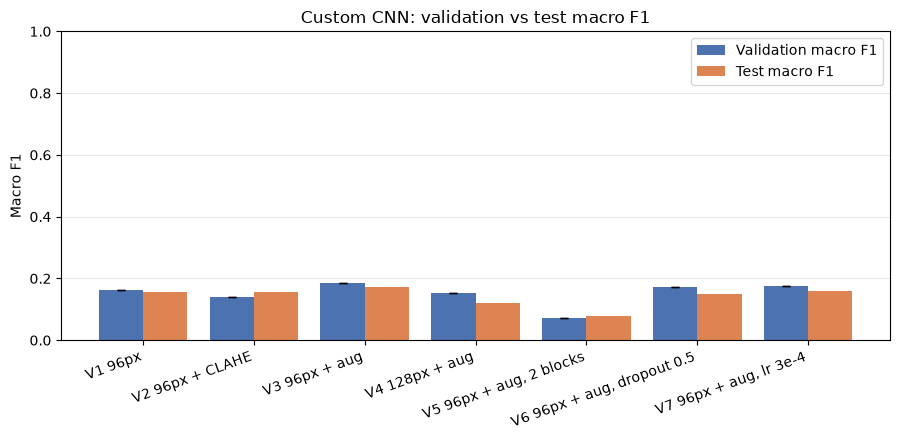

In [7]:
plot_variety_comparison(results, f"{MODEL_NAME}: validation vs test macro F1",
                        f"{MEMBER}_variety_comparison.png")

### Learning curves of the best variety

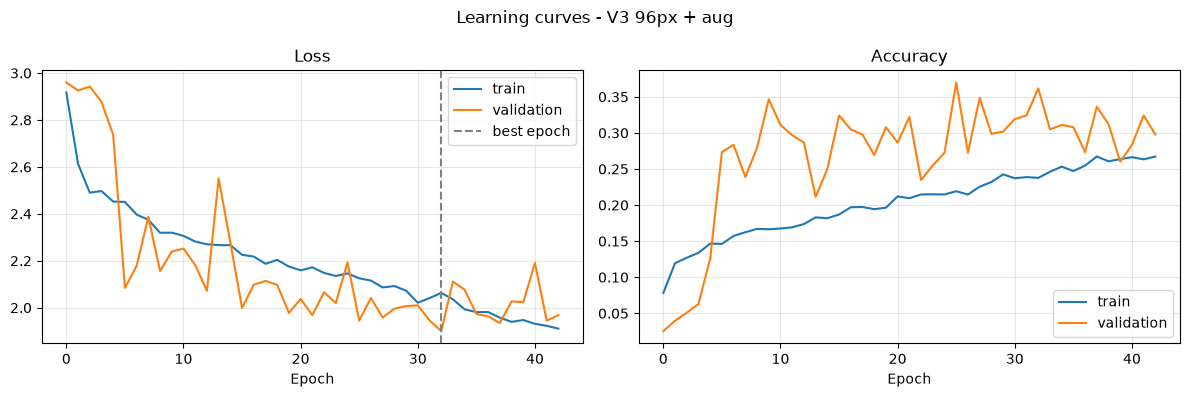

In [8]:
best_name = results.loc[results["val_macro_f1"].idxmax(), "variety"]
best_run = runs[best_name]
h = best_run["history"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(h["loss"], label="train")
axes[0].plot(h["val_loss"], label="validation")
axes[0].axvline(best_run["best_epoch"] - 1, color="grey", linestyle="--", label="best epoch")
axes[0].set_title("Loss")
axes[1].plot(h["accuracy"], label="train")
axes[1].plot(h["val_accuracy"], label="validation")
axes[1].set_title("Accuracy")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)
fig.suptitle(f"Learning curves - {best_name}")
plt.tight_layout()
plt.savefig(Path("../..") / "results" / "model_figures" / f"{MEMBER}_learning_curves.png", dpi=120)
plt.show()

## 5b. 3-fold cross-validation of the best variety

The variety comparison used one hold-out validation set. To check the winner is not a lucky split, it is
retrained with **stratified 3-fold CV** on train + validation (6,559 images), for a fixed number of epochs
(its best epoch from early stopping), so no fold ever sees its own test images. 3 folds instead of 5 keeps
the CPU training time reasonable.

In [9]:
cfg = best_run["config"]
data = load_images(cfg["image_size"], cfg["clahe"], verbose=False)
X_dev = np.concatenate([data["X_train"], data["X_val"]])
y_dev = np.concatenate([data["y_train"], data["y_val"]])
set_seeds()
with Timer() as t:
    cv_mean, cv_std, fold_scores = cross_validate_keras(
        lambda: build_cnn(cfg["image_size"], cfg["augment"], cfg["blocks"], cfg["dropout"], cfg["learning_rate"]),
        X_dev, y_dev, n_splits=3, epochs=best_run["best_epoch"], batch_size=BATCH_SIZE,
        use_class_weight=True, make_callbacks=lambda: [lr_schedule()])
print(f"3-fold CV macro F1 = {cv_mean:.3f} +/- {cv_std:.3f}  ({t.seconds / 60:.1f} min)")
best_idx = results.index[results["variety"] == best_name][0]
results.loc[best_idx, ["cv_macro_f1", "cv_macro_f1_std"]] = [cv_mean, cv_std]
results.loc[best_idx, "validation"] += "; best re-checked with 3-fold CV"

  fold 1/3: macro F1 = 0.1345


  fold 2/3: macro F1 = 0.1337


  fold 3/3: macro F1 = 0.1580
3-fold CV macro F1 = 0.142 +/- 0.011  (28.1 min)


## 6. Best variety on the held-out test set

Best variety (chosen on validation, never on test): V3 96px + aug
                precision    recall  f1-score   support

         coral      0.367     0.425     0.394       348
          crab      0.043     0.091     0.059        11
         diver      0.182     0.154     0.167        13
           eel      0.000     0.000     0.000        41
          fish      0.604     0.409     0.488       538
  fishInGroups      0.230     0.278     0.252        72
      flatworm      0.000     0.000     0.000        13
     jellyfish      0.250     0.240     0.245        25
marine_dolphin      0.000     0.000     0.000        10
       octopus      0.062     0.200     0.095        10
       rayfish      0.408     0.305     0.349        95
    seaAnemone      0.401     0.525     0.455       221
   seaCucumber      0.000     0.000     0.000        10
       seaSlug      0.115     0.300     0.167        20
     seaUrchin      0.113     0.621     0.191        29
         shark      0.250     0.105  

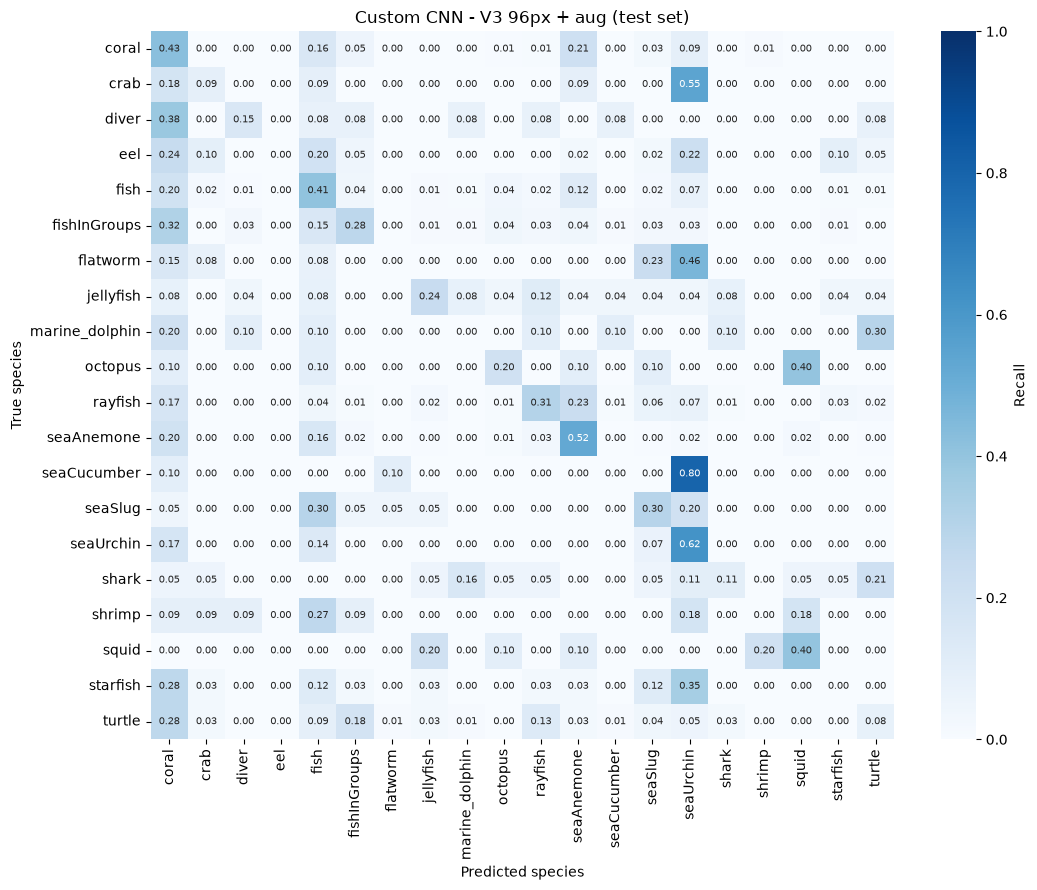

In [10]:
print("Best variety (chosen on validation, never on test):", best_name)
class_names = best_run["class_names"]
y_test, y_pred = best_run["y_test"], best_run["test_pred"]
best = results.loc[best_idx]
print_report(y_test, y_pred, class_names)
plot_confusion_matrix(y_test, y_pred, class_names, f"{MODEL_NAME} - {best_name} (test set)",
                      f"{MEMBER}_confusion_matrix.png")

In [11]:
save_results(MEMBER, MODEL_NAME, results, best_variety=best_name)
save_predictions(MEMBER, MODEL_NAME, best["variety"], y_test, y_pred)

Saved 7 rows for IT25101088 to C:\Users\nesal\Downloads\Sliit\AIML\GROUP_ID_final\results\outputs\model_results\IT25101088.csv


## 7. Conclusion

**Best variety: V3 - 96x96 px, no CLAHE, data augmentation, 3 conv blocks, dropout 0.3, learning rate 0.001,
balanced class weights** (hold-out validation macro F1 = 0.184; **3-fold CV macro F1 = 0.142 +/- 0.011**).
On the test set: **macro F1 = 0.171**, accuracy = 0.360.

| Finding | Evidence |
|---|---|
| Augmentation helped | Validation macro F1 0.164 -> 0.184 (test 0.156 -> 0.171); the model kept improving for longer (best epoch 33 vs 18) because augmented images are harder to memorise |
| CLAHE hurt | 0.164 without vs 0.140 with CLAHE |
| Depth matters | 2 conv blocks: 0.072 vs 3 blocks: 0.184 - the shallower network cannot build up enough feature detectors |
| Bigger images did not help on a CPU | 128 px: 0.153 - training stopped at epoch 16, before the larger network converged |
| Dropout 0.5 / learning rate 3e-4 | 0.172 / 0.176 - close to, but not better than, the defaults |
| The training fixes worked | A first version (no class weights, max 30 epochs, patience 6) reached only 0.119 test macro F1 |

**What this means:** the learning curves show the CNN is **still underfitting** when it stops - training accuracy
is ~27% and still rising (validation accuracy is higher than training accuracy because augmentation and dropout
only make *training* harder). A small network trained from scratch on ~5.5k images, on a CPU, does not have
enough data or compute to beat hand-crafted HOG + colour features with classical models. The 3-fold CV score is
lower than the hold-out score because each fold trains on only two-thirds of the data. It is competitive on large
classes (fish 0.49, sea anemone 0.45 test F1) and on divers (0.17, better than most models), but scores 0 on six
species. With a GPU, larger images and longer training - or pretrained features - a CNN would be expected to
lead; here it shows the cost of learning features from scratch.

## 8. Limitations and possible improvements

- **CPU budget:** 50 epochs maximum and small images (96/128 px) - a GPU would allow 224 px and deeper networks.
- **Small dataset for training from scratch:** ~5.5k training images for 20 classes, and only 17 training
  images for octopus/marine_dolphin, so rare species are learned poorly.
- **Early stopping on validation loss** is noisy with only 984 validation images; stopping on validation
  macro F1 could suit the imbalanced data better.
- **Only one hold-out run per variety:** random initialisation noise can change rankings between close
  varieties; CV was only affordable for the final model.
- **Improvements:** longer training (on a GPU), oversampling of rare species, focal loss,
  or (outside this module's scope) transfer learning from a pretrained network.